In [1]:
import torch
import torch.nn as nn
import numpy as np

print("PyTorch version:", torch.__version__)
print("Libraries imported successfully!")

PyTorch version: 2.14.1+cpu
Libraries imported successfully!


In [2]:
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

import urllib.request

urllib.request.urlretrieve(url, "input.txt")

with open("input.txt", "r", encoding="utf-8") as f:
    text = f.read()

print(text[:500])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


In [3]:
print("Total characters:", len(text))

print("First 100 characters:")
print(text[:100])

print("Last 100 characters:")
print(text[-100:])

Total characters: 1115394
First 100 characters:
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You
Last 100 characters:
TONIO:
Noble Sebastian,
Thou let'st thy fortune sleep--die, rather; wink'st
Whiles thou art waking.



In [4]:
chars = sorted(list(set(text)))

vocab_size = len(chars)

print("Vocabulary:", ''.join(chars))
print("Vocabulary size:", vocab_size)

Vocabulary: 
 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
Vocabulary size: 65


In [5]:
stoi = {ch: i for i, ch in enumerate(chars)}

itos = {i: ch for i, ch in enumerate(chars)}

print(stoi)

{'\n': 0, ' ': 1, '!': 2, '$': 3, '&': 4, "'": 5, ',': 6, '-': 7, '.': 8, '3': 9, ':': 10, ';': 11, '?': 12, 'A': 13, 'B': 14, 'C': 15, 'D': 16, 'E': 17, 'F': 18, 'G': 19, 'H': 20, 'I': 21, 'J': 22, 'K': 23, 'L': 24, 'M': 25, 'N': 26, 'O': 27, 'P': 28, 'Q': 29, 'R': 30, 'S': 31, 'T': 32, 'U': 33, 'V': 34, 'W': 35, 'X': 36, 'Y': 37, 'Z': 38, 'a': 39, 'b': 40, 'c': 41, 'd': 42, 'e': 43, 'f': 44, 'g': 45, 'h': 46, 'i': 47, 'j': 48, 'k': 49, 'l': 50, 'm': 51, 'n': 52, 'o': 53, 'p': 54, 'q': 55, 'r': 56, 's': 57, 't': 58, 'u': 59, 'v': 60, 'w': 61, 'x': 62, 'y': 63, 'z': 64}


In [6]:
def encode(s):
    return [stoi[c] for c in s]

def decode(numbers):
    return ''.join([itos[i] for i in numbers])

In [7]:
sample = "hello"

encoded = encode(sample)

decoded = decode(encoded)

print("Original:", sample)
print("Encoded:", encoded)
print("Decoded:", decoded)

Original: hello
Encoded: [46, 43, 50, 50, 53]
Decoded: hello


In [8]:
data = torch.tensor(encode(text), dtype=torch.long)

print("Dataset shape:", data.shape)
print("First 20 token IDs:", data[:20])

Dataset shape: torch.Size([1115394])
First 20 token IDs: tensor([18, 47, 56, 57, 58,  1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 14, 43, 44,
        53, 56])


In [9]:
split = int(0.9 * len(data))

train_data = data[:split]

val_data = data[split:]

print("Training data:", len(train_data))
print("Validation data:", len(val_data))

Training data: 1003854
Validation data: 111540


In [10]:
import torch
import torch.nn as nn

print("PyTorch ready!")

PyTorch ready!


In [11]:
embedding_dim = 4

embedding = nn.Embedding(
    num_embeddings=vocab_size,
    embedding_dim=embedding_dim
)

print(embedding)

Embedding(65, 4)


In [12]:
token_id = torch.tensor([0])

result = embedding(token_id)

print("Token ID:", token_id)
print("Embedding:", result)
print("Shape:", result.shape)

Token ID: tensor([0])
Embedding: tensor([[-1.8107, -0.2698, -0.8416, -1.2899]], grad_fn=<EmbeddingBackward0>)
Shape: torch.Size([1, 4])


In [13]:
token_ids = torch.tensor([0, 1, 2, 3, 4])

result = embedding(token_ids)

print(result)
print("Shape:", result.shape)

tensor([[-1.8107, -0.2698, -0.8416, -1.2899],
        [-0.3214,  0.8925,  2.6924,  0.6500],
        [ 0.4868, -2.5062, -0.3102, -0.2933],
        [ 0.0168,  0.2077,  0.9169,  0.0423],
        [ 0.5815, -1.6897, -0.8297, -0.0679]], grad_fn=<EmbeddingBackward0>)
Shape: torch.Size([5, 4])


In [14]:
print("Embedding table:")
print(embedding.weight)

print("Embedding table shape:")
print(embedding.weight.shape)

Embedding table:
Parameter containing:
tensor([[-1.8107, -0.2698, -0.8416, -1.2899],
        [-0.3214,  0.8925,  2.6924,  0.6500],
        [ 0.4868, -2.5062, -0.3102, -0.2933],
        [ 0.0168,  0.2077,  0.9169,  0.0423],
        [ 0.5815, -1.6897, -0.8297, -0.0679],
        [ 0.3651,  2.6762,  0.6453, -0.1956],
        [-0.6931, -0.0485,  0.8197,  1.2649],
        [ 1.2701,  1.3521,  0.6858,  0.5831],
        [ 0.8025,  0.5083, -0.5347,  1.1183],
        [-0.0304,  0.4425,  0.0096,  0.8894],
        [ 2.4400, -0.4322, -0.4525, -0.7885],
        [ 0.1807, -1.1160,  0.5524, -2.1512],
        [-0.9187,  0.4097, -0.9929,  0.0403],
        [ 0.4441,  1.2148, -0.9145, -0.1468],
        [ 1.2807,  0.9413, -1.0692,  0.7661],
        [-1.0528,  1.2557, -0.0088,  0.1340],
        [ 0.1725, -0.1289, -1.6601, -0.3758],
        [-0.8169, -2.3570, -0.2650, -1.2484],
        [ 0.4433, -1.5741, -0.9102,  0.6913],
        [-0.5353, -0.8840, -0.6434,  0.2759],
        [ 0.4263,  0.3317,  0.6994, -2.14

In [15]:
block_size = 32
embedding_dim = 4

position_embedding = nn.Embedding(
    num_embeddings=block_size,
    embedding_dim=embedding_dim
)

print(position_embedding.weight.shape)

torch.Size([32, 4])


In [16]:
token_ids = torch.tensor([0, 1, 2, 3, 4])

positions = torch.arange(5)

token_emb = embedding(token_ids)

position_emb = position_embedding(positions)

final_emb = token_emb + position_emb

print("Token embeddings:", token_emb.shape)
print("Position embeddings:", position_emb.shape)
print("Final embeddings:", final_emb.shape)

Token embeddings: torch.Size([5, 4])
Position embeddings: torch.Size([5, 4])
Final embeddings: torch.Size([5, 4])


In [17]:
print(final_emb)
print("Shape:", final_emb.shape)

tensor([[-2.7274,  0.7108, -1.8687, -2.5427],
        [ 0.2954, -0.4148,  3.6542,  1.5735],
        [ 1.0962, -3.5965, -0.0208, -0.7643],
        [ 0.0631, -1.6952,  3.2762, -0.2021],
        [ 0.4151, -1.9340, -0.5116,  0.5435]], grad_fn=<AddBackward0>)
Shape: torch.Size([5, 4])


In [18]:
x = final_emb.unsqueeze(0)

print(x.shape)

torch.Size([1, 5, 4])


In [19]:
batch_size = 1
sequence_length = 5
embedding_dim = 4

query_layer = nn.Linear(embedding_dim, embedding_dim, bias=False)
key_layer = nn.Linear(embedding_dim, embedding_dim, bias=False)
value_layer = nn.Linear(embedding_dim, embedding_dim, bias=False)

Q = query_layer(x)
K = key_layer(x)
V = value_layer(x)

print("Q shape:", Q.shape)
print("K shape:", K.shape)
print("V shape:", V.shape)

Q shape: torch.Size([1, 5, 4])
K shape: torch.Size([1, 5, 4])
V shape: torch.Size([1, 5, 4])


In [20]:
scores = Q @ K.transpose(-2, -1)

print(scores)
print("Score shape:", scores.shape)

tensor([[[-0.2347,  0.7079, -1.1151, -0.1370, -0.1872],
         [ 3.2403, -3.0396,  2.1251, -0.3259,  0.0401],
         [ 0.5162,  0.2507, -1.5835, -0.0204, -1.2258],
         [ 3.2515, -3.0638,  1.7624, -0.5419, -0.0893],
         [ 0.2678,  0.8316, -1.9184,  0.2586, -1.3119]]],
       grad_fn=<UnsafeViewBackward0>)
Score shape: torch.Size([1, 5, 5])


In [21]:
#Scaling the scores
import math

scores = scores / math.sqrt(embedding_dim)

print(scores)

tensor([[[-0.1173,  0.3540, -0.5575, -0.0685, -0.0936],
         [ 1.6202, -1.5198,  1.0625, -0.1629,  0.0201],
         [ 0.2581,  0.1253, -0.7917, -0.0102, -0.6129],
         [ 1.6258, -1.5319,  0.8812, -0.2709, -0.0446],
         [ 0.1339,  0.4158, -0.9592,  0.1293, -0.6559]]],
       grad_fn=<DivBackward0>)


In [22]:
mask = torch.tril(torch.ones(sequence_length, sequence_length))

print(mask)

tensor([[1., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0.],
        [1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1.]])


In [23]:
scores = scores.masked_fill(mask == 0, float('-inf'))

print(scores)

tensor([[[-0.1173,    -inf,    -inf,    -inf,    -inf],
         [ 1.6202, -1.5198,    -inf,    -inf,    -inf],
         [ 0.2581,  0.1253, -0.7917,    -inf,    -inf],
         [ 1.6258, -1.5319,  0.8812, -0.2709,    -inf],
         [ 0.1339,  0.4158, -0.9592,  0.1293, -0.6559]]],
       grad_fn=<MaskedFillBackward0>)


In [24]:
#Apply Softmax
attention_weights = torch.softmax(scores, dim=-1)

print(attention_weights)

tensor([[[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.9585, 0.0415, 0.0000, 0.0000, 0.0000],
         [0.4493, 0.3934, 0.1573, 0.0000, 0.0000],
         [0.5997, 0.0255, 0.2848, 0.0900, 0.0000],
         [0.2433, 0.3225, 0.0815, 0.2422, 0.1104]]],
       grad_fn=<SoftmaxBackward0>)


In [25]:
print(attention_weights.sum(dim=-1))

tensor([[1.0000, 1.0000, 1.0000, 1.0000, 1.0000]], grad_fn=<SumBackward1>)


In [26]:
output = attention_weights @ V

print("Attention output:")
print(output)

print("Output shape:", output.shape)

Attention output:
tensor([[[-2.1469, -1.0987,  2.1207, -0.3839],
         [-2.0010, -0.9798,  1.9480, -0.3832],
         [-0.4715,  0.0451,  0.1292, -0.3670],
         [-1.3045, -0.8014,  1.0620, -0.3634],
         [-0.0027,  0.4018, -0.4933, -0.3830]]], grad_fn=<UnsafeViewBackward0>)
Output shape: torch.Size([1, 5, 4])


In [27]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

batch_size = 16
block_size = 32
n_embd = 128
num_heads = 4
dropout = 0.1

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)
print("Embedding dimension:", n_embd)
print("Attention heads:", num_heads)

Device: cpu
Embedding dimension: 128
Attention heads: 4


In [28]:
token_embedding_table = nn.Embedding(vocab_size, n_embd)

position_embedding_table = nn.Embedding(block_size, n_embd)

In [29]:
def get_batch(split):
    source = train_data if split == "train" else val_data

    ix = torch.randint(
        len(source) - block_size - 1,
        (batch_size,)
    )

    x = torch.stack([source[i:i+block_size] for i in ix])
    y = torch.stack([source[i+1:i+block_size+1] for i in ix])

    return x.to(device), y.to(device)

In [30]:
xb, yb = get_batch("train")

print("Input shape:", xb.shape)
print("Target shape:", yb.shape)

Input shape: torch.Size([16, 32])
Target shape: torch.Size([16, 32])


In [31]:
class Head(nn.Module):

    def __init__(self, head_size):
        super().__init__()

        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)

        self.register_buffer(
            "tril",
            torch.tril(torch.ones(block_size, block_size))
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):

        B, T, C = x.shape

        k = self.key(x)
        q = self.query(x)

        scores = q @ k.transpose(-2, -1)

        scores = scores * (k.shape[-1] ** -0.5)

        scores = scores.masked_fill(
            self.tril[:T, :T] == 0,
            float("-inf")
        )

        weights = F.softmax(scores, dim=-1)

        weights = self.dropout(weights)

        v = self.value(x)

        output = weights @ v

        return output


In [32]:
class MultiHeadAttention(nn.Module):

    def __init__(self, num_heads, head_size):
        super().__init__()

        self.heads = nn.ModuleList([
            Head(head_size) for _ in range(num_heads)
        ])

        self.projection = nn.Linear(
            num_heads * head_size,
            n_embd
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):

        outputs = [head(x) for head in self.heads]

        combined = torch.cat(outputs, dim=-1)

        output = self.projection(combined)

        return self.dropout(output)

In [33]:
class FeedForward(nn.Module):

    def __init__(self, n_embd):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.network(x)

In [34]:
class TransformerBlock(nn.Module):

    def __init__(self, n_embd, num_heads):
        super().__init__()

        head_size = n_embd // num_heads

        self.attention = MultiHeadAttention(
            num_heads,
            head_size
        )

        self.feed_forward = FeedForward(n_embd)

        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):

        x = x + self.attention(self.ln1(x))

        x = x + self.feed_forward(self.ln2(x))

        return x

In [35]:
token_emb = token_embedding_table(xb)

positions = torch.arange(block_size, device=device)

pos_emb = position_embedding_table(positions)

x = token_emb + pos_emb

print("Combined embedding shape:", x.shape)

Combined embedding shape: torch.Size([16, 32, 128])


In [36]:
transformer = TransformerBlock(
    n_embd,
    num_heads
).to(device)

x = transformer(x)

print("Transformer output shape:", x.shape)

Transformer output shape: torch.Size([16, 32, 128])


In [37]:
class GPTLanguageModel(nn.Module):

    def __init__(self):
        super().__init__()

        # Convert character IDs into embeddings
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)

        # Give the model information about character positions
        self.position_embedding_table = nn.Embedding(block_size, n_embd)

        # Two Transformer blocks
        self.blocks = nn.Sequential(
            TransformerBlock(n_embd, num_heads),
            TransformerBlock(n_embd, num_heads)
        )

        # Normalize the final representations
        self.final_layer_norm = nn.LayerNorm(n_embd)

        # Predict the next character
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):

        B, T = idx.shape

        # Token embeddings
        token_emb = self.token_embedding_table(idx)

        # Position embeddings
        positions = torch.arange(T, device=idx.device)
        pos_emb = self.position_embedding_table(positions)

        # Combine token and position information
        x = token_emb + pos_emb

        # Pass through Transformer blocks
        x = self.blocks(x)

        # Final normalization
        x = self.final_layer_norm(x)

        # Predict next character
        logits = self.lm_head(x)

        loss = None

        if targets is not None:

            B, T, C = logits.shape

            logits = logits.view(B * T, C)
            targets = targets.view(B * T)

            loss = F.cross_entropy(logits, targets)

        return logits, loss

In [38]:
model = GPTLanguageModel().to(device)

print("Model created successfully!")

Model created successfully!


In [39]:
total_params = sum(p.numel() for p in model.parameters())

print("Total parameters:", total_params)

Total parameters: 416833


In [40]:
xb, yb = get_batch("train")

logits, loss = model(xb, yb)

print("Input shape:", xb.shape)
print("Target shape:", yb.shape)
print("Prediction shape:", logits.shape)
print("Initial loss:", loss.item())

Input shape: torch.Size([16, 32])
Target shape: torch.Size([16, 32])
Prediction shape: torch.Size([512, 65])
Initial loss: 4.409527778625488


In [41]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4
)

print("Optimizer created successfully!")

Optimizer created successfully!


In [42]:
xb, yb = get_batch("train")

logits, loss = model(xb, yb)

optimizer.zero_grad()

loss.backward()

optimizer.step()

print("Loss:", loss.item())
print("One training update completed!")

Loss: 4.35292911529541
One training update completed!


In [43]:
@torch.no_grad()
def estimate_loss():

    out = {}

    model.eval()

    for split in ["train", "val"]:

        losses = torch.zeros(20)

        for k in range(20):

            X, Y = get_batch(split)

            logits, loss = model(X, Y)

            losses[k] = loss.item()

        out[split] = losses.mean().item()

    model.train()

    return out

In [44]:
losses = estimate_loss()

print("Training loss:", losses["train"])
print("Validation loss:", losses["val"])

Training loss: 4.33462381362915
Validation loss: 4.309780120849609


In [45]:
max_iters = 1000
eval_interval = 200

print("Training iterations:", max_iters)
print("Evaluation interval:", eval_interval)

Training iterations: 1000
Evaluation interval: 200


In [46]:
for step in range(max_iters):

    # Evaluate the model periodically
    if step % eval_interval == 0:
        losses = estimate_loss()

        print(
            f"Step {step}: "
            f"Training loss {losses['train']:.4f}, "
            f"Validation loss {losses['val']:.4f}"
        )

    # Get a batch of training data
    xb, yb = get_batch("train")

    # Forward propagation
    logits, loss = model(xb, yb)

    # Clear previous gradients
    optimizer.zero_grad(set_to_none=True)

    # Backpropagation
    loss.backward()

    # Update model parameters
    optimizer.step()

print("Training completed!")

Step 0: Training loss 4.3334, Validation loss 4.3172
Step 200: Training loss 2.5617, Validation loss 2.5714
Step 400: Training loss 2.4144, Validation loss 2.4023
Step 600: Training loss 2.3340, Validation loss 2.3191
Step 800: Training loss 2.2405, Validation loss 2.2703
Training completed!


In [47]:
for step in range(max_iters):

    # Evaluate the model periodically
    if step % eval_interval == 0:
        losses = estimate_loss()

        print(
            f"Step {step}: "
            f"Training loss {losses['train']:.4f}, "
            f"Validation loss {losses['val']:.4f}"
        )

    # Get a batch of training data
    xb, yb = get_batch("train")

    # Forward propagation
    logits, loss = model(xb, yb)

    # Clear previous gradients
    optimizer.zero_grad(set_to_none=True)

    # Backpropagation
    loss.backward()

    # Update model parameters
    optimizer.step()

print("Training completed!")

Step 0: Training loss 2.2017, Validation loss 2.2145
Step 200: Training loss 2.1623, Validation loss 2.2023
Step 400: Training loss 2.0989, Validation loss 2.1528
Step 600: Training loss 2.0721, Validation loss 2.0981
Step 800: Training loss 2.0403, Validation loss 2.0698
Training completed!


In [48]:
def generate(self, idx, max_new_tokens):

    for _ in range(max_new_tokens):

        # Keep only the latest block_size characters
        idx_cond = idx[:, -block_size:]

        # Get predictions
        logits, loss = self(idx_cond)

        # Get predictions for the final character position
        logits = logits[:, -1, :]

        # Convert scores into probabilities
        probabilities = F.softmax(logits, dim=-1)

        # Select the next character
        next_token = torch.multinomial(probabilities, num_samples=1)

        # Append the new character
        idx = torch.cat((idx, next_token), dim=1)

    return idx


GPTLanguageModel.generate = generate

In [49]:
context = torch.zeros((1, 1), dtype=torch.long, device=device)

generated = model.generate(context, max_new_tokens=500)

print(decode(generated[0].tolist()))


beidellant of the thow couns mese,
A op his a Rome wean
For than hom pursele of tas oftry!

And pould, there husbad I mede yake my bole word to have bate'll youckwe him is forRincy light?

Soldrrone freftear
Nomth:
Whide couns:
And so dogh for on noty not age will,
Thy In bou, asand in onds ben.

QUEE You, yor fres yone.
WARD I; aly, ke ande?
Inds good mith:
GodySeing thoref rrinder goilid lave.

INCETIONUL:
O, my mooree; Ho wankreming on aghmandy mearthou reged
Tost of ef son! ysur hid onces th


In [50]:
prompt = "ROMEO"

context = torch.tensor(
    [encode(prompt)],
    dtype=torch.long,
    device=device
)

generated = model.generate(context, max_new_tokens=300)

print(decode(generated[0].tolist()))

ROMEOLPENG:
Petall; a thait
The I yed Sow, makesh more, hers thelling sich stie, this ingo al

Mat I boine with Kire! make low My. ABUM's Ge
And and, Do spand wejlive roverm me.

LIABED:
For arn the senting ficcinke
I Forystice: they pad, and, durs
You awor rad heis yilns thacist not gearbe;
's am hid Go


In [51]:
additional_iters = 4000

for step in range(additional_iters):

    if step % 500 == 0:
        losses = estimate_loss()

        print(
            f"Additional step {step}: "
            f"Training loss {losses['train']:.4f}, "
            f"Validation loss {losses['val']:.4f}"
        )

    xb, yb = get_batch("train")

    logits, loss = model(xb, yb)

    optimizer.zero_grad(set_to_none=True)

    loss.backward()

    optimizer.step()

print("Additional training completed!")

Additional step 0: Training loss 2.0091, Validation loss 2.0667
Additional step 500: Training loss 1.9386, Validation loss 1.9949
Additional step 1000: Training loss 1.9113, Validation loss 1.9638
Additional step 1500: Training loss 1.8410, Validation loss 1.9266
Additional step 2000: Training loss 1.8096, Validation loss 1.9543
Additional step 2500: Training loss 1.8280, Validation loss 1.9168
Additional step 3000: Training loss 1.7498, Validation loss 1.9089
Additional step 3500: Training loss 1.7782, Validation loss 1.8857
Additional training completed!


In [52]:
prompt = "ROMEO"

context = torch.tensor(
    [encode(prompt)],
    dtype=torch.long,
    device=device
)

model.eval()

generated = model.generate(context, max_new_tokens=300)

print(decode(generated[0].tolist()))

model.train()

ROMEO:
No, must the and, Petan:
Wee laoking make us them he ollientled cannot:
The and out my quitains?

Nor Murdon
Farstion yet charkhus life; anry wild,
No he giving take you me, on by any to:
'Tis not not,-
Deciontle tultent
With not besuit? it, withing thy remberaly and do thus so chuld hight shilt M


GPTLanguageModel(
  (token_embedding_table): Embedding(65, 128)
  (position_embedding_table): Embedding(32, 128)
  (blocks): Sequential(
    (0): TransformerBlock(
      (attention): MultiHeadAttention(
        (heads): ModuleList(
          (0-3): 4 x Head(
            (key): Linear(in_features=128, out_features=32, bias=False)
            (query): Linear(in_features=128, out_features=32, bias=False)
            (value): Linear(in_features=128, out_features=32, bias=False)
            (dropout): Dropout(p=0.1, inplace=False)
          )
        )
        (projection): Linear(in_features=128, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (feed_forward): FeedForward(
        (network): Sequential(
          (0): Linear(in_features=128, out_features=512, bias=True)
          (1): GELU(approximate='none')
          (2): Linear(in_features=512, out_features=128, bias=True)
          (3): Dropout(p=0.1, inplace=False)
        )
      )
      (ln

In [53]:
torch.save(model.state_dict(), "mini_gpt.pth")

In [54]:
loaded_model = GPTLanguageModel().to(device)

loaded_model.load_state_dict(
    torch.load("mini_gpt.pth", map_location=device)
)

loaded_model.eval()

print("Saved Mini-GPT loaded successfully!")

Saved Mini-GPT loaded successfully!


In [55]:
prompt = "ROMEO"

context = torch.tensor(
    [encode(prompt)],
    dtype=torch.long,
    device=device
)

generated = loaded_model.generate(
    context,
    max_new_tokens=300
)

print(decode(generated[0].tolist()))

ROMEO:
It we he knot
Theld WheNo, and pyicessen: if givising them---
All then Right stay, yet flandier;
But their acceard, take and what to be revath core,
Yorighntlen feount he from my so in to to more!
Gent, a such onjakes, and and not the to with we for heart'd hold. The wirl O my plikent proyep,
Or y


In [56]:
from google.colab import files

files.download("mini_gpt.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [57]:
final_losses = estimate_loss()

print("Final training loss:", final_losses["train"])
print("Final validation loss:", final_losses["val"])

Final training loss: 1.714264154434204
Final validation loss: 1.8693262338638306


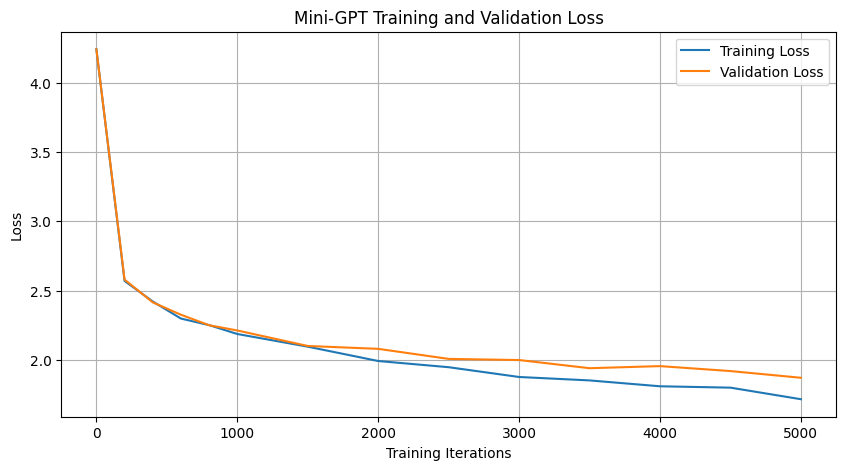

In [58]:
import matplotlib.pyplot as plt

steps = [
    0, 200, 400, 600, 800,
    1000, 1500, 2000, 2500,
    3000, 3500, 4000, 4500, 5000
]

training_loss = [
    4.2445, 2.5694, 2.4208, 2.2974, 2.2500,
    2.1858, 2.0942, 1.9905, 1.9457,
    1.8750, 1.8502, 1.8078, 1.7979,
    final_losses["train"]
]

validation_loss = [
    4.2436, 2.5792, 2.4147, 2.3251, 2.2492,
    2.2113, 2.0992, 2.0785, 2.0058,
    1.9975, 1.9385, 1.9536, 1.9178,
    final_losses["val"]
]

plt.figure(figsize=(10, 5))

plt.plot(steps, training_loss, label="Training Loss")
plt.plot(steps, validation_loss, label="Validation Loss")

plt.xlabel("Training Iterations")
plt.ylabel("Loss")
plt.title("Mini-GPT Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.savefig("training_loss.png", dpi=300, bbox_inches="tight")
plt.show()

In [59]:
import os

print("Graph exists:", os.path.exists("training_loss.png"))

Graph exists: True


In [60]:
from google.colab import files

files.download("training_loss.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [61]:
sample_text = """ROMEO:
And he my a pailt coman their an thy Gorg by sworld
Leain frier to unce be this not pray like,
To you, think hour antoot! the fears, and steecont offly turch
That kill edping Right tath, will as must gof tidery scuctlaine
"""

with open("generated_text.txt", "w") as f:
    f.write(sample_text)

print("Generated text saved!")

Generated text saved!


In [62]:
files.download("generated_text.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>